# Plotting style

Relevant links:
* http://seaborn.pydata.org/tutorial/aesthetics.html
* https://seaborn.pydata.org/generated/seaborn.catplot.html
* https://seaborn.pydata.org/generated/seaborn.barplot.html

In [1]:
from rics import configure_stuff

configure_stuff()

👻 Configured some stuff just the way I like it!

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

## Plain plots (using plt)

In [3]:
def sinplot(flip=1):
    x = np.linspace(0, 14, 100)
    for i in range(1, 7):
        plt.plot(x, np.sin(x + i * 0.5) * (7 - i) * flip)
    plt.suptitle("Suptitle")

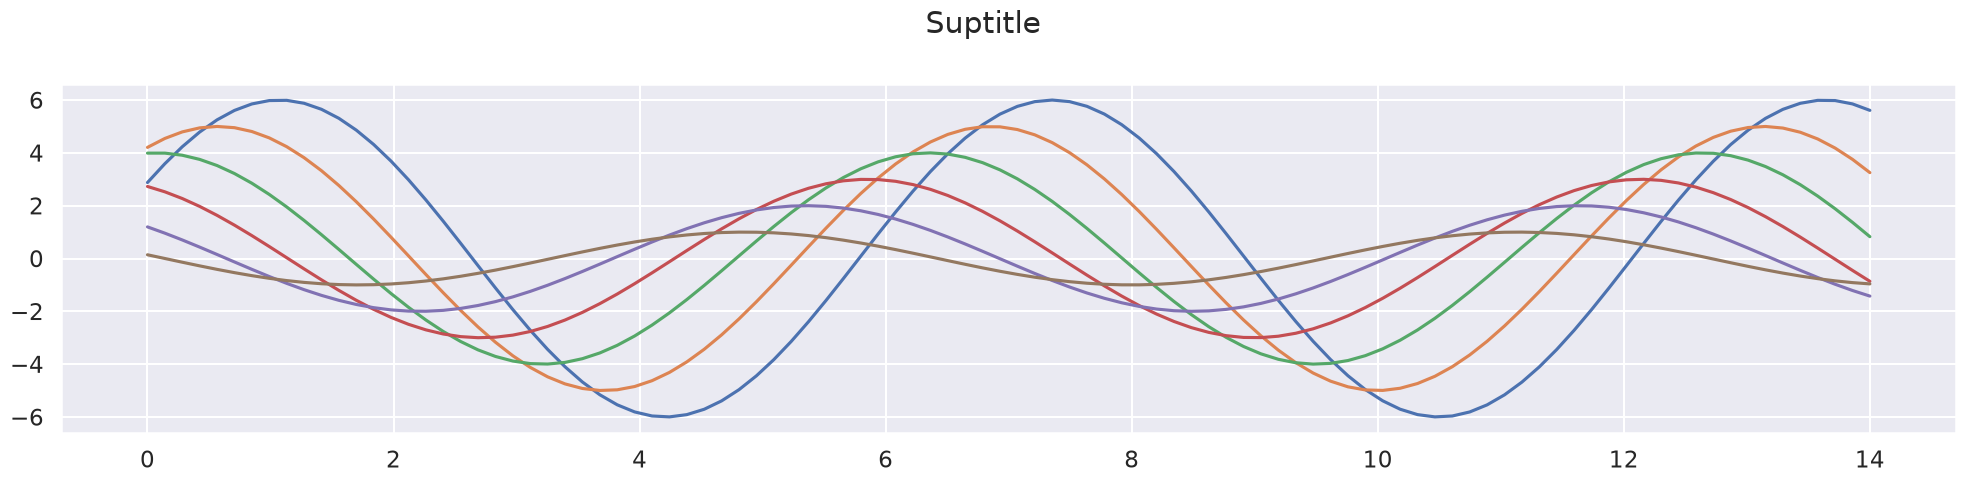

In [4]:
sinplot()

## Seaborn: Barplot

In [5]:
tips = sns.load_dataset("tips")

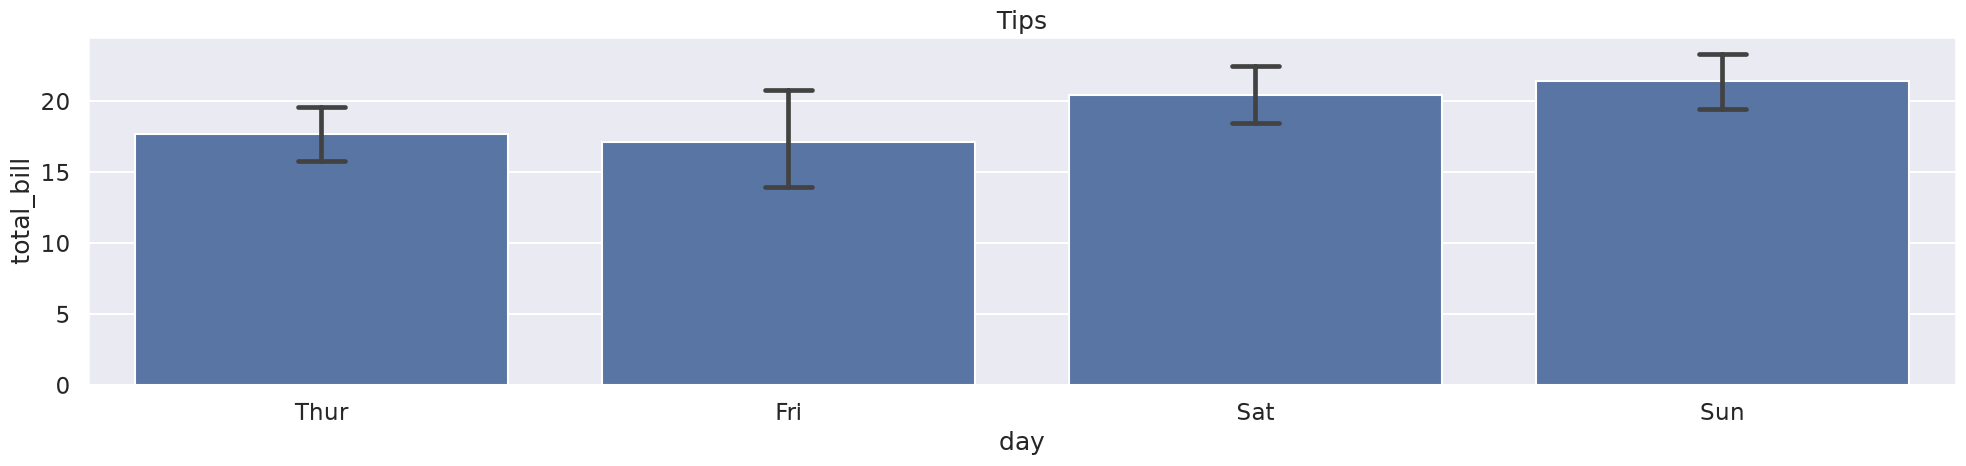

In [6]:
sns.barplot(x="day", y="total_bill", data=tips).set_title("Tips");

## Seaborn: Catplot

In [7]:
titanic = sns.load_dataset("titanic")

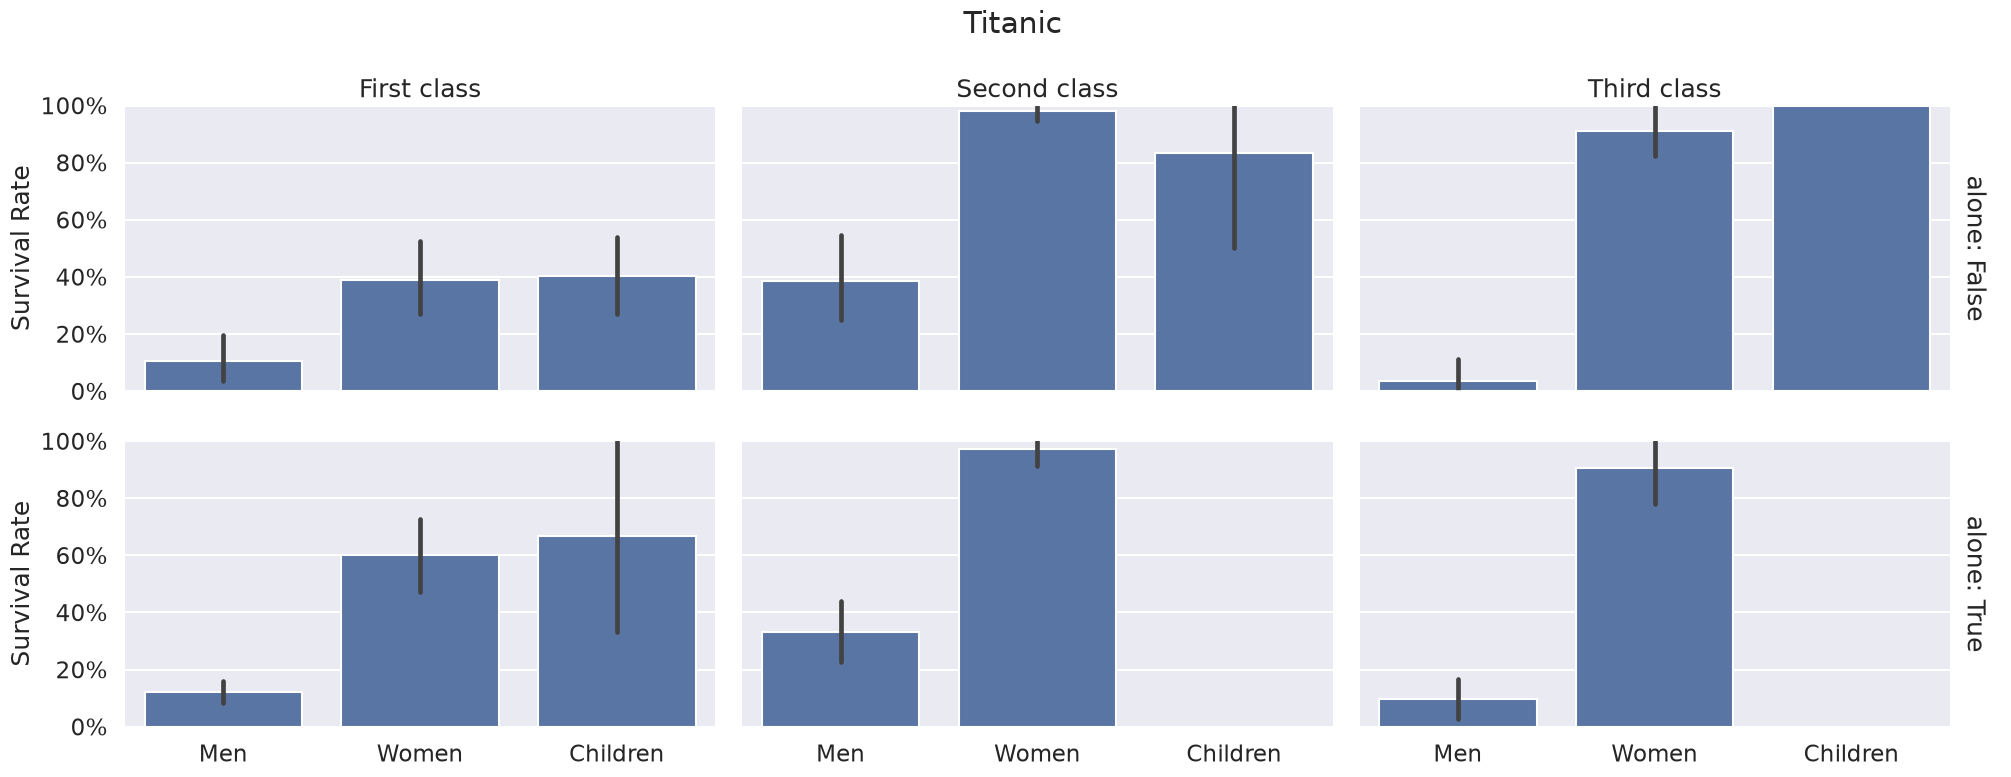

In [8]:
# No use "partialing" catplot since it breaks too easily depending on user preferences. There's no foolproof way to set
# a figsize either without doing some really hacky stuff
g = sns.catplot(
    x="who",
    y="survived",
    col="class",
    row="alone",
    data=titanic,
    kind="bar",
    order=["man", "woman", "child"],
    margin_titles=True,
)

(
    g.set_axis_labels("", "Survival Rate")
    .set_xticklabels(["Men", "Women", "Children"])
    .set_titles(row_template="{row_var}: {row_name}", col_template="{col_name} {col_var}")
    .set(ylim=(0, 1))
    .despine(left=True)
)


g.fig.suptitle("Titanic")
g.fig.set_size_inches((20, 8))
g.fig.tight_layout()  # Figure title overlaps with subplot titles without this

from matplotlib.ticker import PercentFormatter

percent_formatter = PercentFormatter(1.0)
for ax in g.axes.flatten():
    ax.yaxis.set_major_formatter(percent_formatter)